In [1]:
import pandas as pd
import numpy as np

# 1. Load the test-loan predictions from Phase 6
pred = pd.read_parquet("../data/processed/test_predictions.parquet")
print("Test loans:", len(pred))

# 2. 20 equal risk buckets by predicted default probability (1 = safest 5%, 20 = riskiest 5%)
pred["risk_bucket"] = pd.qcut(pred["pd_xgb"].rank(method="first"), 20, labels=range(1, 21)).astype(int)

# 3. Summary per bucket
buckets = pred.groupby("risk_bucket").agg(
    loans=("id", "count"),
    funded=("funded_amnt", "sum"),
    defaults=("is_default", "sum"),
    net_profit=("net_profit", "sum"),
    avg_pd=("pd_xgb", "mean"),
    avg_int_rate=("int_rate", "mean"),
)
buckets["default_rate_pct"] = (buckets["defaults"] / buckets["loans"] * 100).round(2)
buckets["return_pct"] = (buckets["net_profit"] / buckets["funded"] * 100).round(2)
buckets["avg_pd_pct"] = (buckets["avg_pd"] * 100).round(2)
buckets["avg_int_rate"] = buckets["avg_int_rate"].round(2)

# 4. Portfolio if we approve everyone (the starting point)
total_profit = buckets["net_profit"].sum()
total_funded = buckets["funded"].sum()
print(f"Approve all → profit ${total_profit / 1e6:,.1f}M | return {total_profit / total_funded:.2%}\n")

# 5. Save for Excel
buckets.to_csv("../excel/risk_buckets.csv")

buckets[["loans", "avg_pd_pct", "default_rate_pct", "avg_int_rate", "return_pct"]]

Test loans: 445357
Approve all → profit $410.4M | return 7.24%



,loans,avg_pd_pct,default_rate_pct,avg_int_rate,return_pct
risk_bucket,,,,,
1,22268,2.090000,2.43,6.40,7.22
2,22268,3.270000,4.17,7.03,7.44
3,22268,4.190000,5.40,7.58,7.61
4,22268,5.090000,6.51,8.24,7.79
5,22268,5.980000,7.65,8.89,8.18
6,22267,6.870000,8.62,9.52,8.22
7,22268,7.760000,9.61,10.11,8.45
8,22268,8.660000,10.55,10.63,8.75
9,22268,9.580000,11.31,11.14,8.65


Hurdle 0%: best = reject riskiest 0% → economic profit $410.4M
Hurdle 3%: best = reject riskiest 5% → economic profit $242.7M
Hurdle 6%: best = reject riskiest 15% → economic profit $87.5M


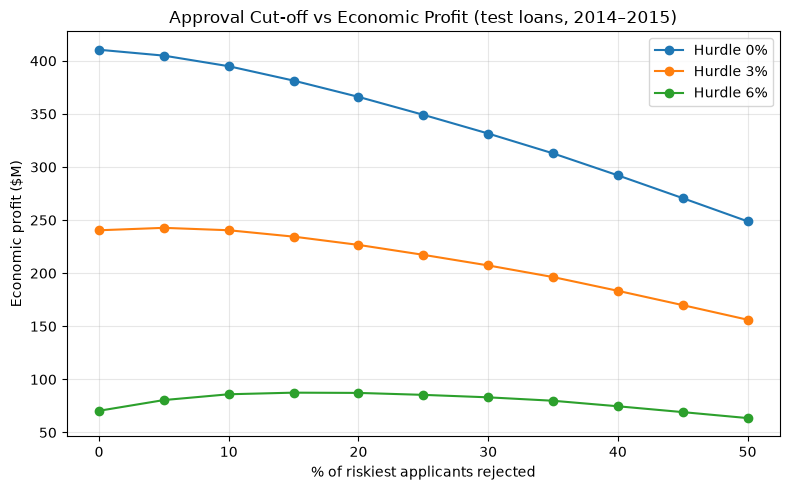

,reject_riskiest_pct,approval_rate_pct,defaults_avoided_pct,approved_default_rate_pct,volume_lost_pct,profit_m,return_pct,econ_profit_0pct_m,econ_profit_3pct_m,econ_profit_6pct_m
0,0,100.0,0.00,14.46,0.00,410.42,7.24,410.42,240.42,70.42
1,5,95.0,11.39,13.49,4.60,404.89,7.49,404.89,242.70,80.52
2,10,90.0,21.03,12.69,9.14,394.91,7.67,394.91,240.44,85.98
3,15,85.0,29.44,12.00,13.57,381.36,7.79,381.36,234.43,87.49
4,20,80.0,37.22,11.35,18.00,366.05,7.88,366.05,226.65,87.25
5,25,75.0,44.29,10.74,22.43,349.16,7.94,349.16,217.29,85.42
6,30,70.0,50.92,10.14,26.93,331.53,8.01,331.53,207.31,83.09
7,35,65.0,57.07,9.55,31.48,312.85,8.06,312.85,196.36,79.87
8,40,60.0,62.66,9.00,36.04,292.14,8.06,292.14,183.40,74.67
9,45,55.0,67.89,8.44,40.74,270.67,8.06,270.67,169.92,69.17


In [2]:
import matplotlib.pyplot as plt

HURDLES = [0.00, 0.03, 0.06]  # lifetime cost of capital (% of amount lent)
total_defaults = buckets["defaults"].sum()
total_loans = buckets["loans"].sum()

rows = []
for k in range(0, 11):  # reject the riskiest k buckets (0% to 50%)
    approved = buckets.loc[buckets.index <= 20 - k]
    row = {
        "reject_riskiest_pct": k * 5,
        "approval_rate_pct": approved["loans"].sum() / total_loans * 100,
        "defaults_avoided_pct": (1 - approved["defaults"].sum() / total_defaults) * 100,
        "approved_default_rate_pct": approved["defaults"].sum() / approved["loans"].sum() * 100,
        "volume_lost_pct": (1 - approved["funded"].sum() / total_funded) * 100,
        "profit_m": approved["net_profit"].sum() / 1e6,
        "return_pct": approved["net_profit"].sum() / approved["funded"].sum() * 100,
    }
    for h in HURDLES:
        econ = approved["net_profit"].sum() - h * approved["funded"].sum()
        row[f"econ_profit_{int(h * 100)}pct_m"] = econ / 1e6
    rows.append(row)

sim = pd.DataFrame(rows).round(2)
sim.to_csv("../excel/policy_simulation.csv", index=False)

# Best cut-off for each hurdle rate
for h in HURDLES:
    col = f"econ_profit_{int(h * 100)}pct_m"
    best = sim.loc[sim[col].idxmax()]
    print(f"Hurdle {h:.0%}: best = reject riskiest {best['reject_riskiest_pct']:.0f}% "
          f"→ economic profit ${best[col]:,.1f}M")

# Chart: economic profit vs cut-off
plt.figure(figsize=(8, 5))
for h in HURDLES:
    plt.plot(sim["reject_riskiest_pct"], sim[f"econ_profit_{int(h * 100)}pct_m"],
             marker="o", label=f"Hurdle {h:.0%}")
plt.xlabel("% of riskiest applicants rejected")
plt.ylabel("Economic profit ($M)")
plt.title("Approval Cut-off vs Economic Profit (test loans, 2014–2015)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../images/policy_simulation.png", dpi=150)
plt.show()

sim

In [3]:
# Risk score from Lending Club's own sub-grade (interest rate breaks ties within a sub-grade)
sub_grade_order = [f"{g}{n}" for g in "ABCDEFG" for n in range(1, 6)]
pred["sub_grade_num"] = pred["sub_grade"].map({sg: i + 1 for i, sg in enumerate(sub_grade_order)})
pred["grade_score"] = pred["sub_grade_num"] + pred["int_rate"] / 100

def evaluate(score_col, reject_pct, hurdle=0.06):
    """Reject the riskiest reject_pct% by score_col and measure the result."""
    risk_rank = pred[score_col].rank(method="first", pct=True)
    approved = pred[risk_rank <= 1 - reject_pct / 100]
    return {
        "defaults_avoided_pct": (1 - approved["is_default"].sum() / total_defaults) * 100,
        "approved_default_rate_pct": approved["is_default"].mean() * 100,
        "econ_profit_6pct_m": (approved["net_profit"].sum() - hurdle * approved["funded_amnt"].sum()) / 1e6,
    }

rows = []
for r in [5, 10, 15, 20]:
    model = evaluate("pd_xgb", r)
    grade = evaluate("grade_score", r)
    rows.append({
        "reject_riskiest_pct": r,
        "defaults_avoided_model_pct": model["defaults_avoided_pct"],
        "defaults_avoided_grade_pct": grade["defaults_avoided_pct"],
        "default_rate_model_pct": model["approved_default_rate_pct"],
        "default_rate_grade_pct": grade["approved_default_rate_pct"],
        "econ_profit_model_m": model["econ_profit_6pct_m"],
        "econ_profit_grade_m": grade["econ_profit_6pct_m"],
    })

model_vs_grade = pd.DataFrame(rows)
model_vs_grade["extra_profit_from_model_m"] = (
    model_vs_grade["econ_profit_model_m"] - model_vs_grade["econ_profit_grade_m"]
)
model_vs_grade = model_vs_grade.round(2)
model_vs_grade.to_csv("../data/processed/model_vs_grade.csv", index=False)
model_vs_grade

,reject_riskiest_pct,defaults_avoided_model_pct,defaults_avoided_grade_pct,default_rate_model_pct,default_rate_grade_pct,econ_profit_model_m,econ_profit_grade_m,extra_profit_from_model_m
0,5,11.39,10.59,13.49,13.61,80.52,74.63,5.89
1,10,21.03,19.58,12.69,12.92,85.98,75.87,10.11
2,15,29.44,27.78,12.00,12.29,87.49,74.77,12.72
3,20,37.22,35.36,11.35,11.68,87.25,72.43,14.81


In [4]:
from importlib.metadata import version

# Python libraries used in this project (with the exact installed versions)
packages = [
    "pandas", "numpy", "pyarrow", "matplotlib", "scikit-learn",
    "xgboost", "shap", "sqlalchemy", "psycopg2-binary", "jupyter", "ipykernel",
]

lines = [f"{p}=={version(p)}" for p in packages]
with open("../requirements.txt", "w") as f:
    f.write("\n".join(lines) + "\n")

print("\n".join(lines))

pandas==3.1.0
numpy==2.5.4
pyarrow==26.0.0
matplotlib==3.11.2
scikit-learn==1.9.1
xgboost==3.4.1
shap==0.54.1
sqlalchemy==2.1.6
psycopg2-binary==2.9.13
jupyter==1.1.1
ipykernel==7.4.0
